# HYCOM ATLb2.00 Currents: surface velocity time series from the virtual Icechunk store

Opens `rtofs_icechunks_v1/` (`/best` group: one daily 00 UTC field per valid day, each from the newest
forecast run) and plots eastward `u`, northward `v` and speed at the surface (Depth 0 m) at two points:

- **Florida Current**, Straits of Florida (25.5° N, 79.9° W): strong, steady northward flow.
- **Loop Current**, eastern Gulf of Mexico (25.5° N, 86.5° W): variable; eddies shed and pass through.

Run from the `rtofs/` folder in the `notebook` conda environment (icechunk 1.x; see README).
Each day at one point reads one source chunk per variable (3 depths × 413 × 563, ≈ 1.2 MB) from TAMU-CC's
server, so the full record at two points is about 1,100 requests (≈ 1.3 GB). Days with no forecast run
(2025-12-11 … 2026-08-19) have no chunk and read as NaN without any request.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from load_rtofs import open_rtofs

best = open_rtofs("best", repo_path="../rtofs_icechunks_v1")
print(f"{best.sizes['time']} days: {str(best.time.values[0])[:10]} to {str(best.time.values[-1])[:10]};"
      f" {best.attrs['missing_days']} days with no run")
best

  2026-11-19T16:13:06.560822Z  WARN icechunk::storage::object_store: The LocalFileSystem storage is not safe for concurrent commits. If more than one thread/process will attempt to commit at the same time, prefer using object stores.
    at icechunk/src/storage/object_store.rs:92



/srv/conda/envs/notebook/lib/python3.11/site-packages/zarr/codecs/numcodecs/_codecs.py:141: ZarrUserWarning: Numcodecs codecs are not in the Zarr version 3 specification and may not be supported by other zarr implementations.
  super().__init__(**codec_config)


527 days: 2025-06-17 to 2026-11-25; 245 days with no run


<xarray.Dataset> Size: 2TB
Dimensions:                  (time: 527, Depth: 33, Y: 3298, X: 4500)
Coordinates:
  * time                     (time) datetime64[ns] 4kB 2025-06-17 ... 2026-11-25
    experiment               (time) <U8 17kB dask.array<chunksize=(527,), meta=np.ndarray>
    lead                     (time) timedelta64[ns] 4kB dask.array<chunksize=(527,), meta=np.ndarray>
    forecast_reference_time  (time) datetime64[ns] 4kB dask.array<chunksize=(527,), meta=np.ndarray>
  * Depth                    (Depth) float32 132B 0.0 10.0 ... 5e+03 5.5e+03
    Latitude                 (Y, X) float32 59MB dask.array<chunksize=(1649, 2250), meta=np.ndarray>
    Longitude                (Y, X) float32 59MB dask.array<chunksize=(1649, 2250), meta=np.ndarray>
Dimensions without coordinates: Y, X
Data variables:
    v                        (time, Depth, Y, X) float32 1TB dask.array<chunksize=(1, 3, 413, 563), meta=np.ndarray>
    u                        (time, Depth, Y, X) float32 1TB dask.array<chunksize=(1, 3, 413, 563), meta=np.ndarray>
Attributes:
    Conventions:        CF-1.8
    title:              Global RTOFS (HYCOM 1/12 deg) ocean velocity, z-level...
    institution:        National Centers for Environmental Prediction
    source:             HYCOM ATLb2.00 (HYCOM archive file), experiments 93.0...
    source_archive:     https://hriai01.tamucc.edu/data/MASTR_MODELS/rtofs/hi...
    source_format:      NetCDF-4/HDF5, zlib level 1, referenced in place (vir...
    layout:             best
    source_file_count:  3680
    metadata_repairs:   Longitude wrapped from the source's 74..794 (modulo 3...
    missing_days:       245
    grid_sha256:        a81a01af6e53f1a1720be00826ee533d7886ea272e89ba73711c1...

## Pick the grid cells

The grid is curvilinear (2-D `Latitude`/`Longitude`), so `sel` by coordinate does not work; find the
nearest cell instead. `Longitude` is in [-180, 180).

In [3]:
%%time
POINTS = {"Florida Current": (25.5, -79.9), "Loop Current": (25.5, -86.5)}

lat, lon = best.Latitude.values, best.Longitude.values      # 59 MB each, stored once
cells = {}
for name, (la, lo) in POINTS.items():
    d2 = (lat - la) ** 2 + ((lon - lo) * np.cos(np.deg2rad(la))) ** 2
    iy, ix = np.unravel_index(np.nanargmin(d2), d2.shape)
    cells[name] = (int(iy), int(ix))
    print(f"{name:16s} Y={iy} X={ix}  ({lat[iy, ix]:.3f} N, {lon[iy, ix]:.3f} E)")

Florida Current  Y=1834 X=2574  (25.513 N, -79.920 E)
Loop Current     Y=1834 X=2492  (25.513 N, -86.480 E)
CPU times: user 595 ms, sys: 319 ms, total: 914 ms
Wall time: 748 ms


## Read u and v at the surface, every day

In [4]:
%%time
series = {}
for name, (iy, ix) in cells.items():
    p = best[["u", "v"]].isel(Depth=0, Y=iy, X=ix).load()
    p["speed"] = np.hypot(p.u, p.v)
    series[name] = p
    n = int(p.u.notnull().sum())
    print(f"{name}: {n} days with data; mean u {float(p.u.mean()):+.2f}, v {float(p.v.mean()):+.2f},"
          f" speed {float(p.speed.mean()):.2f} m/s")

Florida Current: 282 days with data; mean u +0.09, v +1.19, speed 1.20 m/s
Loop Current: 282 days with data; mean u +0.14, v -0.22, speed 0.58 m/s
CPU times: user 20.3 s, sys: 4.24 s, total: 24.5 s
Wall time: 31.6 s


## Time series

Gray band: no forecast run in the archive (2025-12-11 … 2026-08-19), so `/best` is NaN there. Speed is
drawn as the wide pale line behind u and v. Runs up to 2025-07-28 are experiment 93.0; from 2025-07-29 they are 93.1.

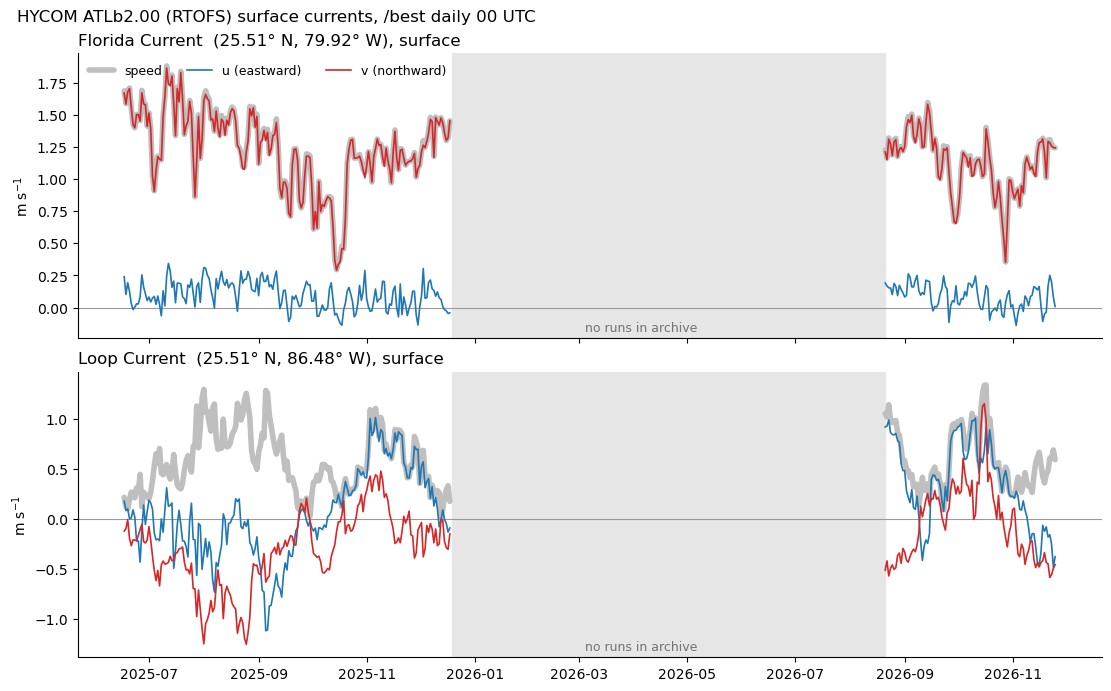

CPU times: user 466 ms, sys: 0 ns, total: 466 ms
Wall time: 465 ms


In [5]:
%%time
def gap_spans(t, ok):
    # (start, end) of runs of missing days
    spans, start = [], None
    for ti, o in zip(t, ok):
        if not o and start is None: start = ti
        if o and start is not None: spans.append((start, ti)); start = None
    if start is not None: spans.append((start, t[-1]))
    return spans

t = best.time.values
exp = best.experiment.values
fig, axes = plt.subplots(len(series), 1, figsize=(11, 3.4 * len(series)), sharex=True, layout="constrained")
for ax, (name, p) in zip(np.atleast_1d(axes), series.items()):
    ax.axhline(0, color="0.6", lw=0.8)
    ax.plot(t, p.speed, color="0.75", lw=4, solid_capstyle="round", label="speed")
    ax.plot(t, p.u, color="#1f77b4", lw=1.2, label="u (eastward)")
    ax.plot(t, p.v, color="#d62728", lw=1.2, label="v (northward)")
    for a, b in gap_spans(t, p.u.notnull().values):
        ax.axvspan(a, b, color="0.9", zorder=0)
    ax.text(0.55, 0.06, "no runs in archive", transform=ax.transAxes, ha="center", va="top", color="0.45", fontsize=9)
    iy, ix = cells[name]
    ax.set_title(f"{name}  ({lat[iy, ix]:.2f}° N, {abs(lon[iy, ix]):.2f}° W), surface", loc="left")
    ax.set_ylabel("m s$^{-1}$")
    for s in ("top", "right"): ax.spines[s].set_visible(False)
axes[0].legend(loc="upper left", bbox_to_anchor=(0, 1.0), ncols=3, frameon=False, fontsize=9)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
fig.suptitle("HYCOM ATLb2.00 (RTOFS) surface currents, /best daily 00 UTC", x=0.01, ha="left")
plt.show()

## Zoom: the 2026 record, with the forecast runs that supplied each day

`lead` is how many days into its run each `/best` day comes from: 1 for most days, longer where a run is
missing. The last seven days are leads 2–8 of the newest run, i.e. **forecasts**, not yet replaced by a
newer run. (Days with no run have `lead` = −1 and are left blank.)

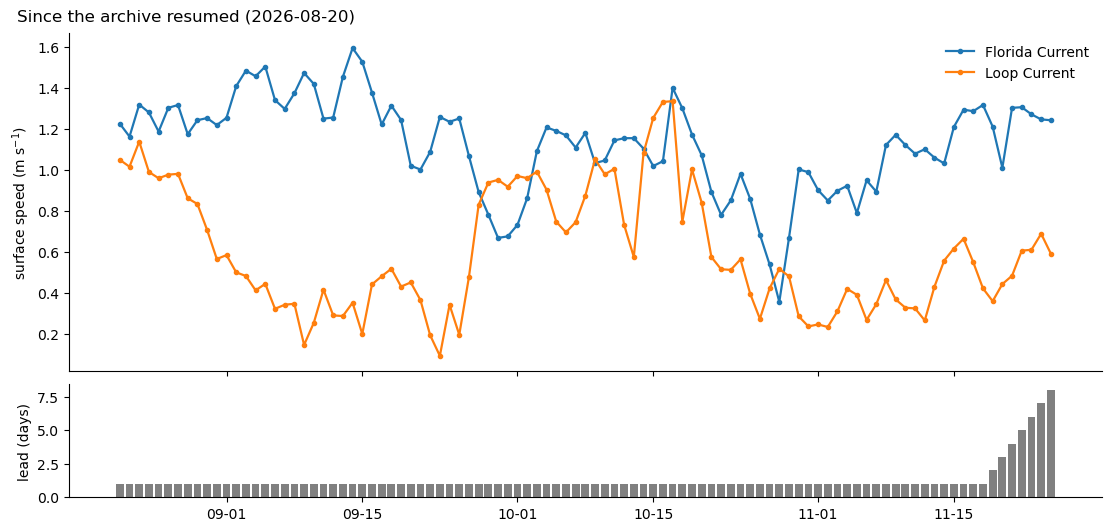

CPU times: user 459 ms, sys: 0 ns, total: 459 ms
Wall time: 458 ms


In [6]:
%%time
recent = slice("2026-08-20", None)
fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True, layout="constrained",
                         gridspec_kw={"height_ratios": [3, 1]})
for name, p in series.items():
    s = p.sel(time=recent)
    axes[0].plot(s.time, s.speed, lw=1.6, marker=".", label=name)
axes[0].set_ylabel("surface speed (m s$^{-1}$)")
axes[0].legend(frameon=False)
lead_days = (best.lead.sel(time=recent) / np.timedelta64(1, "D")).values.astype(float)
lead_days[lead_days < 0] = np.nan        # -1 = no run covers that day
axes[1].bar(best.time.sel(time=recent).values, lead_days, width=0.8, color="0.5")
axes[1].set_ylabel("lead (days)")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
for ax in axes:
    for s in ("top", "right"): ax.spines[s].set_visible(False)
fig.suptitle("Since the archive resumed (2026-08-20)", x=0.01, ha="left")
plt.show()